# Relaxed OLS vs. Alternating Least Squares for the Bilinear Drift Model

Same synthetic dataset throughout (150 scenes, 0.3% noise, truth $\gamma = -0.385$ %/yr).

**The model:** $\rho = [\alpha + \beta g][1 + \gamma t]$, with $g = \cos\theta$.

**Two estimators:**

1. **Relaxed OLS.** Expand the product: $\rho = \alpha + \beta g + p\,t + q\,gt$ with $p = \alpha\gamma$, $q = \beta\gamma$ treated as free coefficients. One `lstsq` call, four parameters, no iteration — but the constraint $p\beta = q\alpha$ is not enforced, and $\gamma$ must be reassembled afterward ($p/\alpha$ or $q/\beta$, which disagree under noise).
2. **ALS.** Enforce the product structure; alternate exact linear solves for $(\alpha,\beta)$ and $\gamma$. Three parameters, iterative, $\gamma$ fitted directly.

Comparison criteria: point estimates, the reassembly discrepancy, bootstrap uncertainty, and iteration cost with/without relaxed-OLS initialization.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams['figure.dpi'] = 110

# --- shared synthetic dataset -------------------------------------
A, B = 0.520, -0.002
C, D = 0.85, 0.18
GAMMA_TRUE = B / A                       # -0.3846 %/yr

N   = 150
t   = np.sort(rng.uniform(0.0, 3.5, N))
sza = rng.uniform(15.0, 55.0, N)
g   = np.cos(np.radians(sza))
rho = (C + D*g) * (A + B*t) * (1 + 0.003*rng.standard_normal(N))

## 1. The two estimators

In [2]:
def fit_relaxed(t, g, rho):
    """Four-column OLS on the expanded polynomial. Returns (alpha, beta, p, q)."""
    X = np.column_stack([np.ones_like(t), g, t, g*t])
    coef, *_ = np.linalg.lstsq(X, rho, rcond=None)
    return coef                                   # [alpha, beta, p, q]

def fit_als(t, g, rho, gamma0=0.0, tol=1e-13, max_iter=500):
    """Constrained bilinear fit. Returns (alpha, beta, gamma, n_iter)."""
    gamma = gamma0
    Xg = np.column_stack([np.ones_like(g), g])
    for it in range(max_iter):
        (alpha, beta), *_ = np.linalg.lstsq(Xg, rho/(1 + gamma*t), rcond=None)
        v = rho/(alpha + beta*g) - 1
        gamma_new = (t @ v) / (t @ t)
        if abs(gamma_new - gamma) < tol:
            return alpha, beta, gamma_new, it + 1
        gamma = gamma_new
    return alpha, beta, gamma, max_iter

In [3]:
a_r, b_r, p_r, q_r = fit_relaxed(t, g, rho)
g_via_p, g_via_q = p_r/a_r, q_r/b_r

a_c, b_c, g_c, n_iter = fit_als(t, g, rho)

print("RELAXED OLS (one shot)")
print(f"  alpha={a_r:.5f}  beta={b_r:.5f}  p={p_r:.6f}  q={q_r:.6f}")
print(f"  gamma via p/alpha : {100*g_via_p:+.3f} %/yr")
print(f"  gamma via q/beta  : {100*g_via_q:+.3f} %/yr")
g_ref = np.cos(np.radians(30.0))
g_at_ref = (p_r + q_r*g_ref) / (a_r + b_r*g_ref)      # drift at reference geometry
print(f"  reassembly disagreement: {100*abs(g_via_p-g_via_q):.3f} %/yr")
print(f"  gamma via drift-at-ref-geometry: {100*g_at_ref:+.3f} %/yr  (the well-conditioned readout)")
print(f"  constraint check p*beta/(q*alpha) = {p_r*b_r/(q_r*a_r):.3f}  (1.0 if structure held)")
print()
print(f"ALS ({n_iter} iterations, cold start)")
print(f"  alpha={a_c:.5f}  beta={b_c:.5f}")
print(f"  gamma             : {100*g_c:+.3f} %/yr")
print()
print(f"truth               : {100*GAMMA_TRUE:+.3f} %/yr")

RELAXED OLS (one shot)
  alpha=0.44144  beta=0.09471  p=-0.001623  q=-0.000708
  gamma via p/alpha : -0.368 %/yr
  gamma via q/beta  : -0.747 %/yr
  reassembly disagreement: 0.380 %/yr
  gamma via drift-at-ref-geometry: -0.427 %/yr  (the well-conditioned readout)
  constraint check p*beta/(q*alpha) = 0.492  (1.0 if structure held)

ALS (86 iterations, cold start)
  alpha=0.44186  beta=0.09418
  gamma             : -0.423 %/yr

truth               : -0.385 %/yr


The relaxed fit produces **two disagreeing gamma candidates** from the naive reassemblies — the price of not enforcing the shared-$\gamma$ structure. $p/\alpha$ behaves far better than $q/\beta$ (it divides by the large, well-determined baseline rather than the small geometry slope). The **drift-at-reference-geometry combination** $(p + q\,g_{ref})/(\alpha + \beta\,g_{ref})$ is the well-conditioned readout of the relaxed fit — it mixes the coefficients in the proportions where their errors cancel, and is the fair comparator to ALS.

## 2. Bootstrap comparison

Same 1000 scene-level resamples fed to both estimators, tracking all three relaxed readouts.

In [4]:
BOOT = 1000
g_ref = np.cos(np.radians(30.0))
boots = {"relaxed p/alpha": [], "relaxed q/beta": [], "relaxed at ref geom": [], "ALS": []}
for _ in range(BOOT):
    idx = rng.integers(0, N, N)
    ti, gi, ri = t[idx], g[idx], rho[idx]
    if np.ptp(ti) < 0.5 or np.ptp(gi) < 0.05:
        continue
    ar, br, pr, qr = fit_relaxed(ti, gi, ri)
    boots["relaxed p/alpha"].append(pr/ar)
    boots["relaxed q/beta"].append(qr/br)
    boots["relaxed at ref geom"].append((pr + qr*g_ref)/(ar + br*g_ref))
    boots["ALS"].append(fit_als(ti, gi, ri)[2])

print(f"{'estimator':>22} {'mean %/yr':>10} {'SE %/yr':>9} {'95% CI':>22}")
for k, v in boots.items():
    v = 100*np.array(v); boots[k] = v
    ci = np.percentile(v, [2.5, 97.5])
    print(f"{k:>22} {v.mean():>+10.3f} {v.std():>9.3f}   [{ci[0]:+.3f}, {ci[1]:+.3f}]")
print(f"{'truth':>22} {100*GAMMA_TRUE:>+10.3f}")

             estimator  mean %/yr   SE %/yr                 95% CI
       relaxed p/alpha     -0.368     0.192   [-0.725, +0.014]
        relaxed q/beta     -0.716     1.131   [-2.881, +1.505]
   relaxed at ref geom     -0.427     0.031   [-0.488, -0.364]
                   ALS     -0.422     0.025   [-0.470, -0.374]
                 truth     -0.385


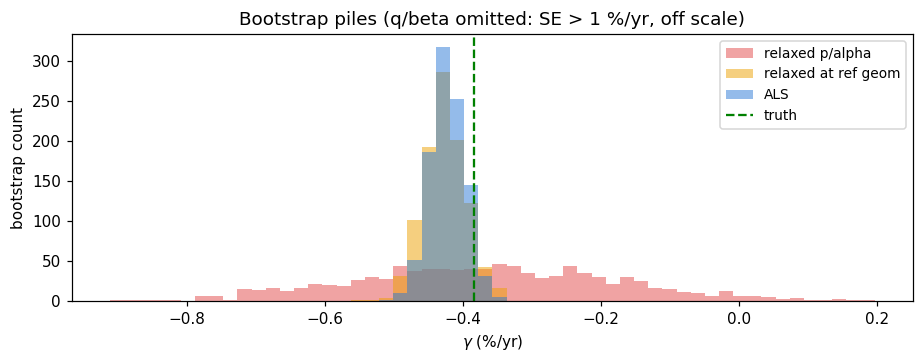

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
show = ["relaxed p/alpha", "relaxed at ref geom", "ALS"]
lo = min(boots[k].min() for k in show); hi = max(boots[k].max() for k in show)
bins = np.linspace(max(lo, -1.2), min(hi, 0.6), 55)
colors = {"relaxed p/alpha": "#e34948", "relaxed at ref geom": "#eda100", "ALS": "#2a78d6"}
for k in show:
    ax.hist(np.clip(boots[k], bins[0], bins[-1]), bins=bins, alpha=0.5, label=k, color=colors[k])
ax.axvline(100*GAMMA_TRUE, color='g', ls='--', lw=1.5, label='truth')
ax.set_xlabel(r'$\gamma$ (%/yr)'); ax.set_ylabel('bootstrap count')
ax.set_title('Bootstrap piles (q/beta omitted: SE > 1 %/yr, off scale)')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 3. Iteration cost: warm-starting ALS from the relaxed fit

In [4]:
_, _, g_cold, n_cold = fit_als(t, g, rho, gamma0=0.0)
_, _, g_warm, n_warm = fit_als(t, g, rho, gamma0=g_via_p)

print(f"cold start (gamma0 = 0)          : {n_cold:>4d} iterations -> {100*g_cold:+.4f} %/yr")
print(f"warm start (gamma0 = p/alpha)    : {n_warm:>4d} iterations -> {100*g_warm:+.4f} %/yr")
print(f"identical answers: {np.isclose(g_cold, g_warm, atol=1e-12)}")

cold start (gamma0 = 0)          :   86 iterations -> -0.4228 %/yr
warm start (gamma0 = p/alpha)    :   78 iterations -> -0.4228 %/yr
identical answers: True


## 4. Summary

| | relaxed OLS | ALS (constrained) |
|---|---|---|
| solve | one `lstsq` call | iterated exact linear solves |
| parameters | 4 (one redundant) | 3 (matches the physics) |
| $\gamma$ readout | assembled; naive ratios are poorly conditioned, ref-geometry combination required | direct fitted parameter |
| bootstrap SE (this data) | 0.03 %/yr with the ref-geometry readout; 0.19 ($p/\alpha$) to 1.1 ($q/\beta$) with naive readouts | 0.025 %/yr |
| product structure | unenforced; $p\beta/(q\alpha)$ ratio is a model-adequacy diagnostic | enforced |

Honest conclusions from this run:

1. **The relaxed fit is only competitive with the correct readout.** With the drift-at-reference-geometry combination it nearly matches ALS (SE 0.031 vs 0.025); with the naive $p/\alpha$ or $q/\beta$ reassemblies it is 8--45x worse. The relaxed route therefore reintroduces exactly the readout-convention machinery the three-parameter form was designed to eliminate.
2. **Warm-starting helps less than expected.** ALS convergence here is governed by the valley geometry (the $\alpha\gamma$ coupling), not the starting point: 86 iterations cold, 78 warm. Since each iteration is microseconds, initialization is a non-issue either way at this scale.
3. **Recommended pattern**: ALS (or scipy `least_squares`) as the estimator, reporting the constrained $\gamma$; the relaxed fit retained not as an accelerator but as a **structure diagnostic** — the per-channel constraint ratio $p\beta/(q\alpha)$ flags channels where the multiplicative decomposition itself fails.